# Повітряні тривоги України: базовий аналіз

Виконаний огляд відтворюваного Python-проєкту. Основне джерело — волонтерський CSV. Прогноз на київську добу створюється о 00:00 Europe/Kyiv. Дві цілі: записані початки та години за об’єднаними інтервалами. Авторські `naive=True` 30 хвилин збережено. Telegram ще не використовується.

Повний експеримент: `python run.py run --workers 4`. Цей notebook читає його артефакти, повторює незалежний аудит і демонструє прогноз із доступного минулого.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    raise RuntimeError('Запустіть notebook з кореня air_raid_analysis')
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from airraid.sources import load_ledger, as_of, snapshot_at, verify_checksums
from airraid.series import midnight, day_hours
from airraid.evaluation import make_tasks
from airraid.models import forecast_task
DATA, REPORTS = ROOT / 'data', ROOT / 'reports'
protocol = json.loads((REPORTS / 'protocol.json').read_text())
snapshots = json.loads((DATA / 'snapshots.json').read_text())
ledger = load_ledger(DATA / 'event_ledger.csv.gz')
print('Перевірено файлів:', verify_checksums(DATA))
display(pd.Series(json.loads((DATA / 'provenance.json').read_text())))

Перевірено файлів: 6


repository             https://github.com/Vadimkin/ukrainian-air-raid...
snapshot_count                                                       100
latest                          bf0c323c78e3e4508721458797dcd38c95df13f3
latest_available_at                                 2026-10-11T04:50:19Z
latest_rows                                                       115989
ledger_versions                                                   115989
earliest_replay_at                                  2026-07-04T03:28:41Z
publication_policy     successful GitHub Actions run completion after...
note                   Base rows are conservatively available only at...
dtype: object

## Перевірка джерела

Дублікати — повний збіг region/started_at/finished_at/naive. Однакова тривалість не є дублікатом. Шість нульових і 14 довгих інтервалів не вилучаються автоматично. Не кожна відсутність запису доводить відсутність реальної тривоги: допуск регіону використовує індикатор недавньої активності, а не незалежний журнал повноти.

In [2]:
audit = json.loads((REPORTS / 'source_audit.json').read_text())
display(pd.Series({k:v for k,v in audit.items() if not isinstance(v, (list, dict))}))
display(pd.read_csv(REPORTS / 'coverage.csv')[['region','eligible','recent_event_days','last_recorded_start']])
duration_minutes = (ledger.finished_at-ledger.started_at).dt.total_seconds()/60
assert (duration_minutes[ledger.naive] == 30).all()
print('Авторські 30 хвилин збережено; дублікати:', audit['duplicate_rows'])

rows                                                                           115989
duplicate_rows                                                                      0
missing_timestamps                                                                  0
negative_durations                                                                  0
zero_durations                                                                      6
over_24_hours                                                                      14
max_duration_hours                                                            178.265
naive_rows                                                                       5812
naive_30_minutes_preserved                                                       True
finished_before_publication                                                      True
source_message_ids_nondecreasing                                                 True
snapshots                                             

,region,eligible,recent_event_days,last_recorded_start
0,Івано-Франківська область,True,2,2026-09-01T18:37:00+00:00
1,Волинська область,True,28,2026-09-11T09:34:18+00:00
2,Вінницька область,True,18,2026-09-12T02:21:00+00:00
3,Дніпропетровська область,True,30,2026-09-12T03:00:46+00:00
4,Донецька область,True,29,2026-09-11T16:25:10+00:00
5,Житомирська область,True,22,2026-09-12T02:28:10+00:00
6,Закарпатська область,False,0,2026-07-30T01:26:50+00:00
7,Запорізька область,True,30,2026-09-12T00:21:34+00:00
8,Київ,True,25,2026-09-11T20:53:24+00:00
9,Київська область,True,29,2026-09-12T02:34:40+00:00


Авторські 30 хвилин збережено; дублікати: 0


## Київська доба та доступність

Показуємо різницю між датою події й датою доступності CSV. Години прогнозуються через частку доби, що автоматично враховує 23/25 годин. Незавершена active-подія не отримує вигаданого finish; відповідна мітка неготова.

In [3]:
display(pd.DataFrame({'date':['2026-03-29','2026-10-25','2026-10-12'],
                      'day_hours':[day_hours(d) for d in ['2026-03-29','2026-10-25','2026-10-12']]}))
origin = midnight(protocol['test_start'])
snapshot = snapshot_at(snapshots, origin)
known = as_of(ledger, origin)
assert (known.available_at <= origin).all()
display(pd.Series({'origin':origin.isoformat(),'snapshot':snapshot['sha'],
                  'snapshot_available_at':snapshot['available_at'],'known_rows':len(known)}))

,date,day_hours
0,2026-03-29,23.0
1,2026-10-25,25.0
2,2026-10-12,24.0


origin                                  2026-09-13T00:00:00+03:00
snapshot                 5c0b2e82dc39171c496726864897a0ae0b012000
snapshot_available_at                        2026-09-12T03:48:54Z
known_rows                                                 111529
dtype: object

## Тренд до фінального тесту

Добові ряди та середні за сім минулих днів. Ряди описують зареєстровані інтервали. Не оцінюємо причинність або грошові втрати.

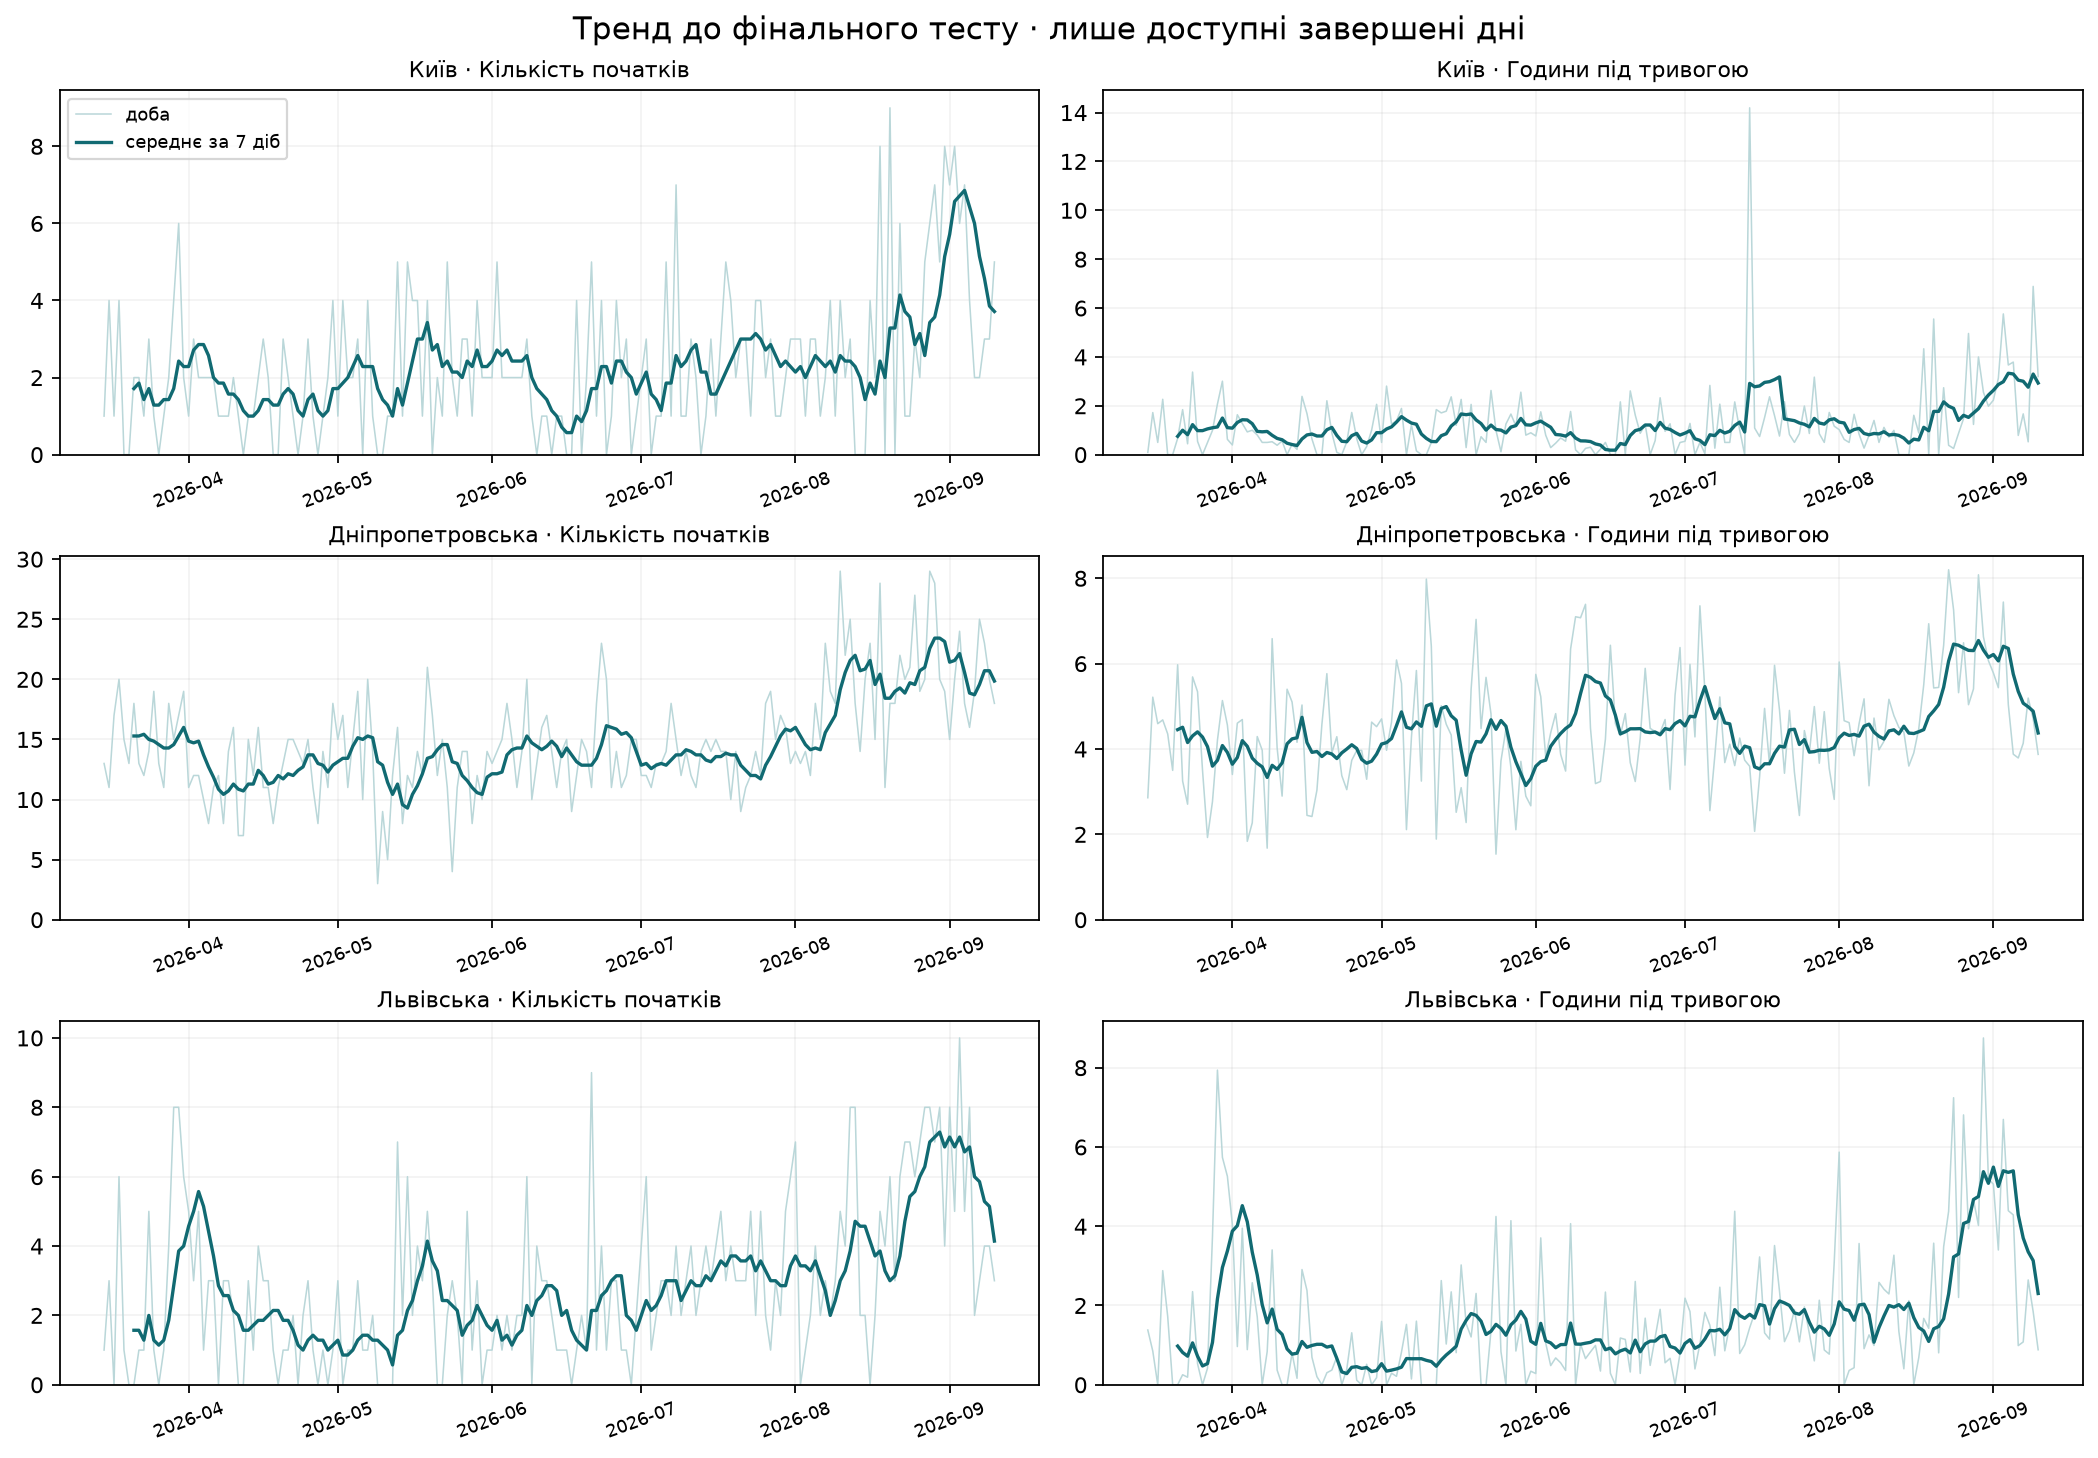

,region,target,recent_n,previous_n,recent_mean,previous_mean,difference
0,Івано-Франківська область,count,27,30,0.074074,0.066667,0.007407
1,Івано-Франківська область,hours,27,30,0.024383,0.033074,-0.008691
2,Волинська область,count,30,30,3.600000,3.833333,-0.233333
3,Волинська область,hours,30,30,3.799148,4.210769,-0.411620
4,Вінницька область,count,30,30,1.900000,0.866667,1.033333
5,Вінницька область,hours,30,30,0.878769,0.354778,0.523991
6,Дніпропетровська область,count,30,30,20.433333,15.433333,5.000000
7,Дніпропетровська область,hours,30,30,5.439769,4.159852,1.279917
8,Донецька область,count,30,30,4.600000,3.533333,1.066667
9,Донецька область,hours,30,30,3.136926,3.136648,0.000278


In [4]:
display(Image(filename=str(REPORTS/'figures/history.png')))
display(pd.read_csv(REPORTS/'trend_comparison.csv').head(12))

## Сезонність до моделювання

Одна зведена фігура з двома шкалами для кількості й годин. Період перед першою валідацією; нульові дні включені за припущенням про покриття. Таблиця містить n, середнє, медіану та відхилення від середнього регіону.

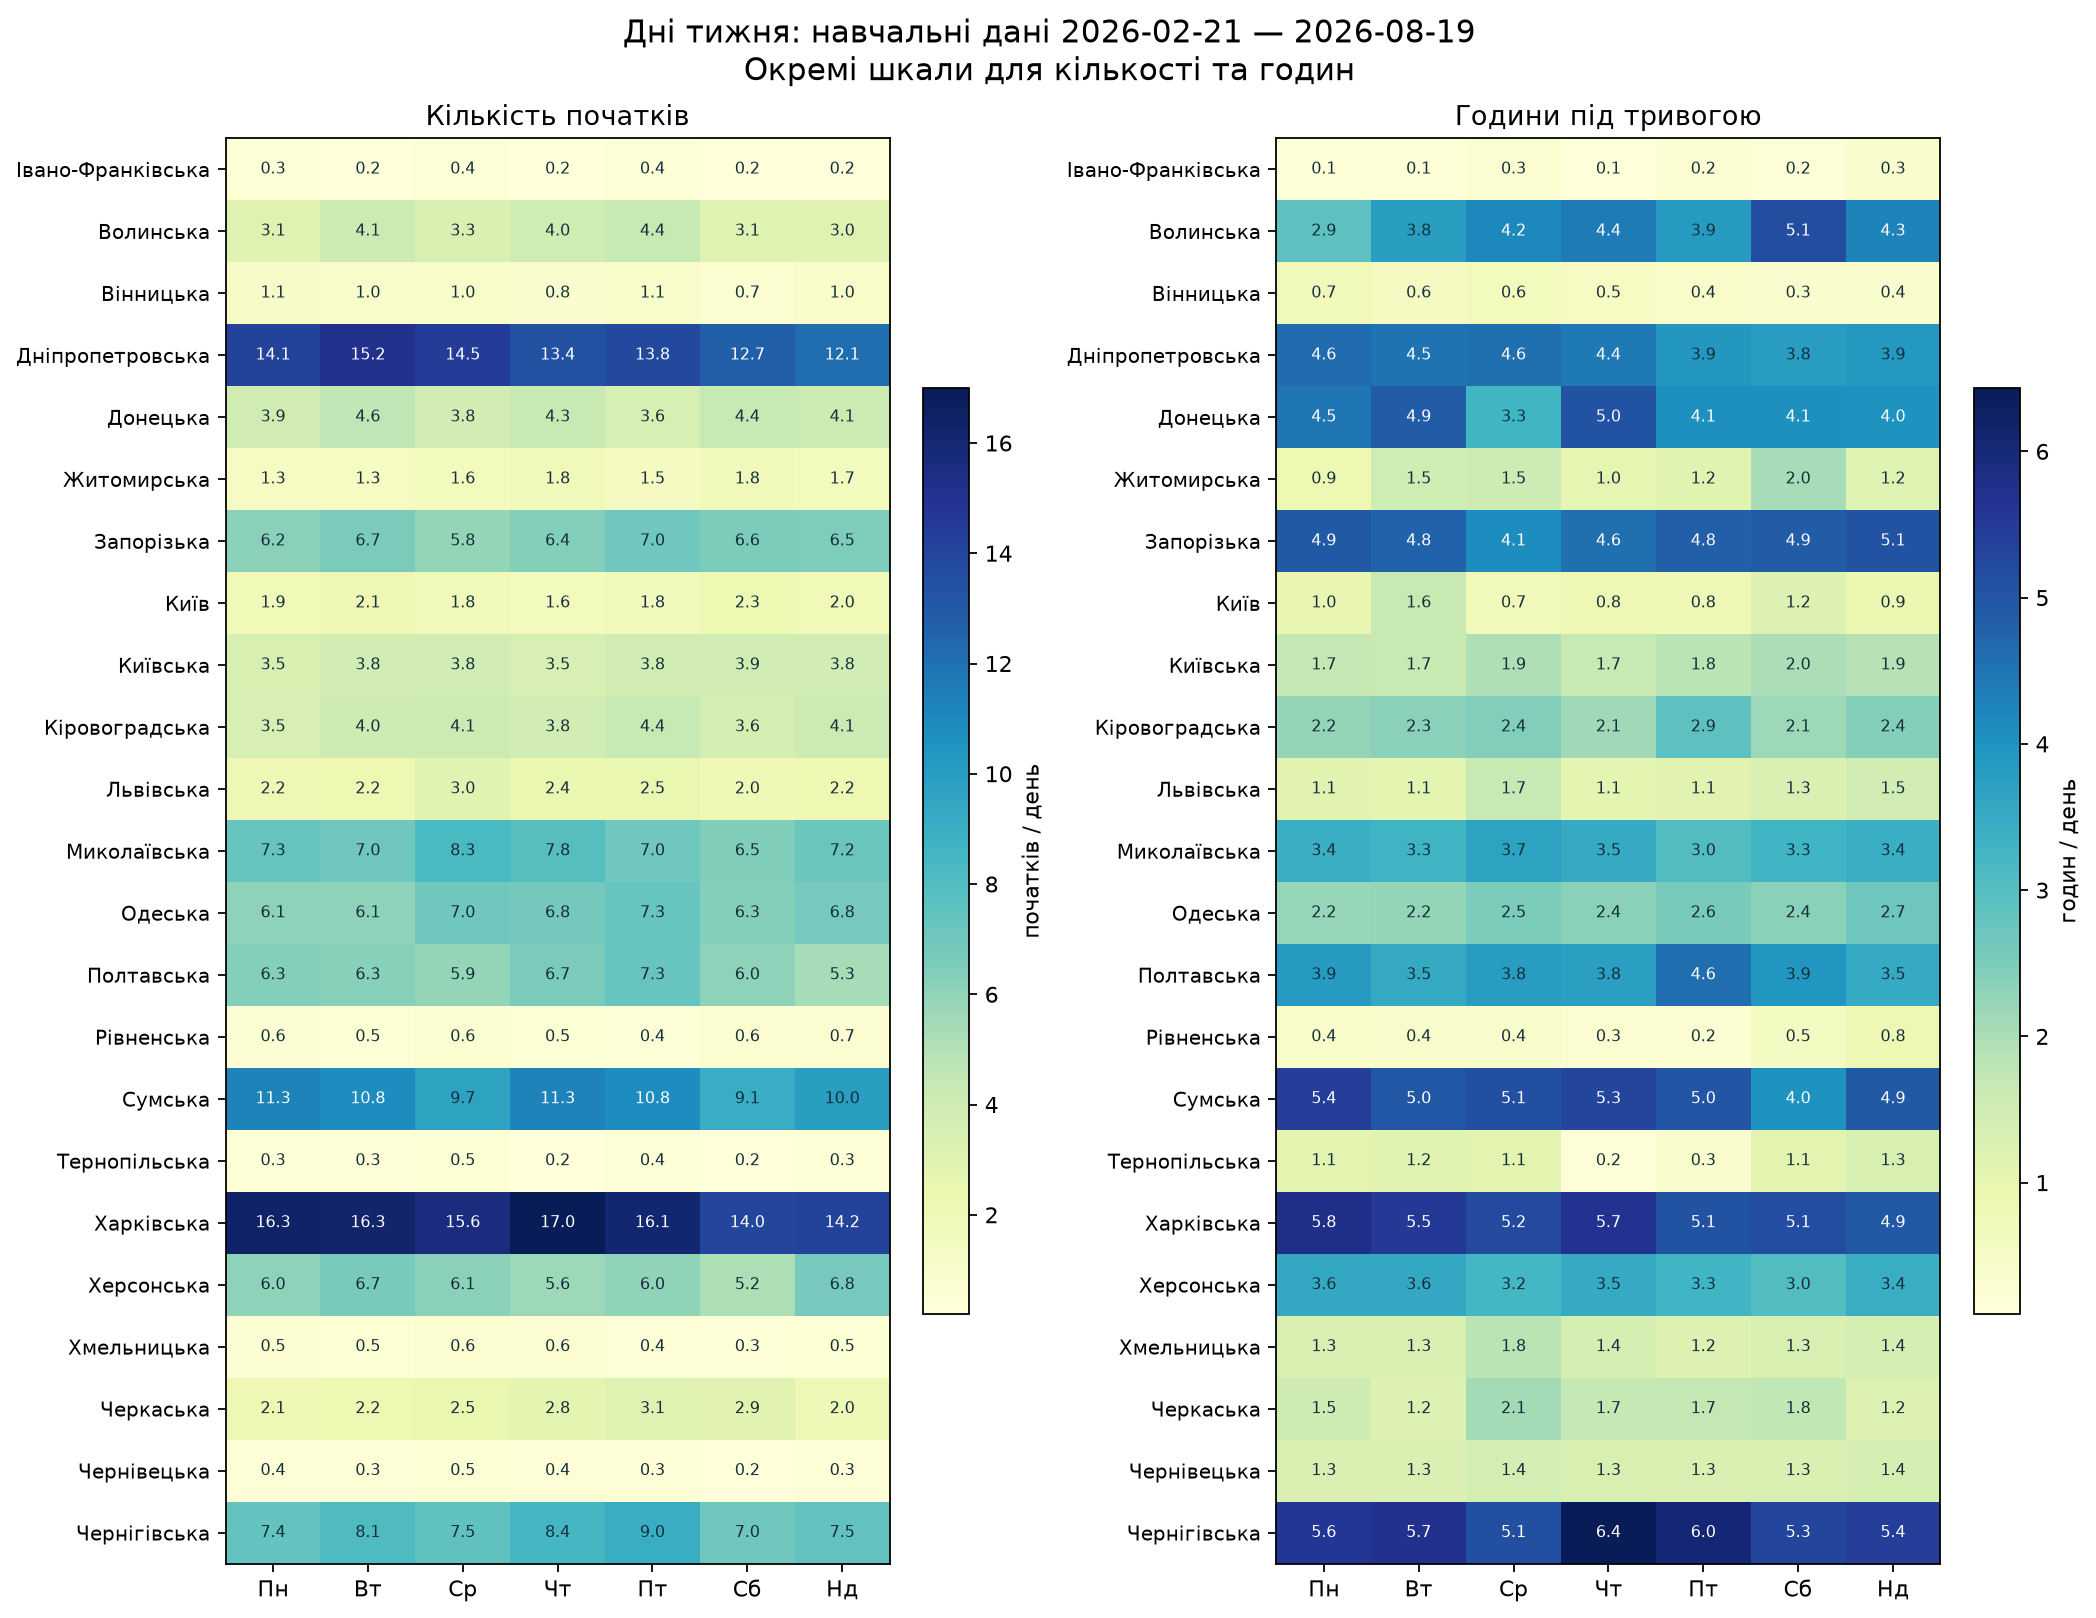

,region,target,weekday,n,mean,median,region_mean,difference_from_region_mean,weekday_name
98,Київ,count,0,26,1.923077,1.500000,1.916667,0.006410,Пн
99,Київ,count,1,26,2.115385,1.500000,1.916667,0.198718,Вт
100,Київ,count,2,26,1.769231,1.000000,1.916667,-0.147436,Ср
101,Київ,count,3,25,1.600000,1.000000,1.916667,-0.316667,Чт
102,Київ,count,4,25,1.760000,2.000000,1.916667,-0.156667,Пт
103,Київ,count,5,26,2.269231,2.000000,1.916667,0.352564,Сб
104,Київ,count,6,26,1.961538,2.000000,1.916667,0.044872,Нд
105,Київ,hours,0,26,0.979615,0.724444,1.016505,-0.036889,Пн
106,Київ,hours,1,26,1.648002,0.874722,1.016505,0.631498,Вт
107,Київ,hours,2,26,0.738739,0.522083,1.016505,-0.277765,Ср


analysis_origin                            2026-08-21T00:00:00+03:00
source_available_at                             2026-08-20T01:23:46Z
snapshot_sha                7f7a546078524cc7feb937a6e80bdf283e74e15d
start                                                     2026-02-21
end                                                       2026-08-19
only_pre_validation_data                                        True
training_rows                                                   4140
censored_rows                                                      0
weekday_mapping_checked                                         True
table_mean_reconciled                                           True
stl_used                                                       False
dtype: object

In [5]:
display(Image(filename=str(REPORTS/'figures/weekday_profiles.png')))
weekday = pd.read_csv(REPORTS/'weekday_differences.csv')
display(weekday.query("region == 'Київ'"))
display(pd.Series(json.loads((REPORTS/'seasonality_audit.json').read_text())))

## ACF і користь сезонного варіанта

Лінійний тренд вилучено. Лаги 7/14/21 є дослідницькими; поточкові межі 95% не враховують багато порівнянь. Пік не є доказом тижневої закономірності. Остаточний варіант вибрано за попередньою валідацією. STL не використовується.

lag                                  7      14     21
region                    target                     
Івано-Франківська область count  -0.082  0.059 -0.112
                          hours  -0.067 -0.017 -0.130
Волинська область         count   0.129  0.080 -0.140
                          hours  -0.043  0.048 -0.081
Вінницька область         count  -0.162  0.001 -0.098
                          hours  -0.131 -0.022  0.036
Дніпропетровська область  count   0.075  0.063 -0.066
                          hours   0.105 -0.102  0.062
Донецька область          count   0.001 -0.088  0.051
                          hours   0.031  0.127 -0.080
Житомирська область       count   0.088  0.040  0.018
                          hours  -0.082 -0.110 -0.096
Запорізька область        count   0.082 -0.110 -0.096
                          hours   0.046  0.036 -0.054
Київ                      count  -0.110  0.031 -0.100
                          hours  -0.045 -0.045  0.005
Київська область          count  -0.066  0.040 -0.111
                          hours   0.104  0.059 -0.162
Кіровоградська область    count  -0.067 -0.046 -0.074
                          hours   0.097  0.041 -0.121
Львівська область         count  -0.031  0.032 -0.046
                          hours   0.011 -0.071 -0.058
Миколаївська область      count  -0.033 -0.000  0.044
                          hours  -0.066 -0.004 -0.043
Одеська область           count   0.062  0.069  0.020
                          hours   0.118  0.059 -0.106
Полтавська область        count  -0.097  0.117 -0.018
                          hours  -0.053  0.010  0.070
Рівненська область        count  -0.027  0.114  0.034
                          hours   0.105 -0.010  0.004
Сумська область           count   0.113  0.001  0.045
                          hours   0.196  0.129  0.069
Тернопільська область     count  -0.090  0.071 -0.141
                          hours  -0.056 -0.074  0.002
Харківська область        count   0.040  0.042  0.039
                          hours   0.025  0.098  0.024
Херсонська область        count  -0.032 -0.025  0.039
                          hours   0.083 -0.004  0.016
Хмельницька область       count  -0.137  0.070 -0.140
                          hours  -0.071 -0.055 -0.000
Черкаська область         count  -0.186  0.047 -0.025
                          hours  -0.034 -0.026 -0.022
Чернівецька область       count  -0.091  0.038 -0.094
                          hours  -0.042 -0.108  0.015
Чернігівська область      count  -0.049  0.065  0.012
                          hours  -0.203  0.144 -0.043

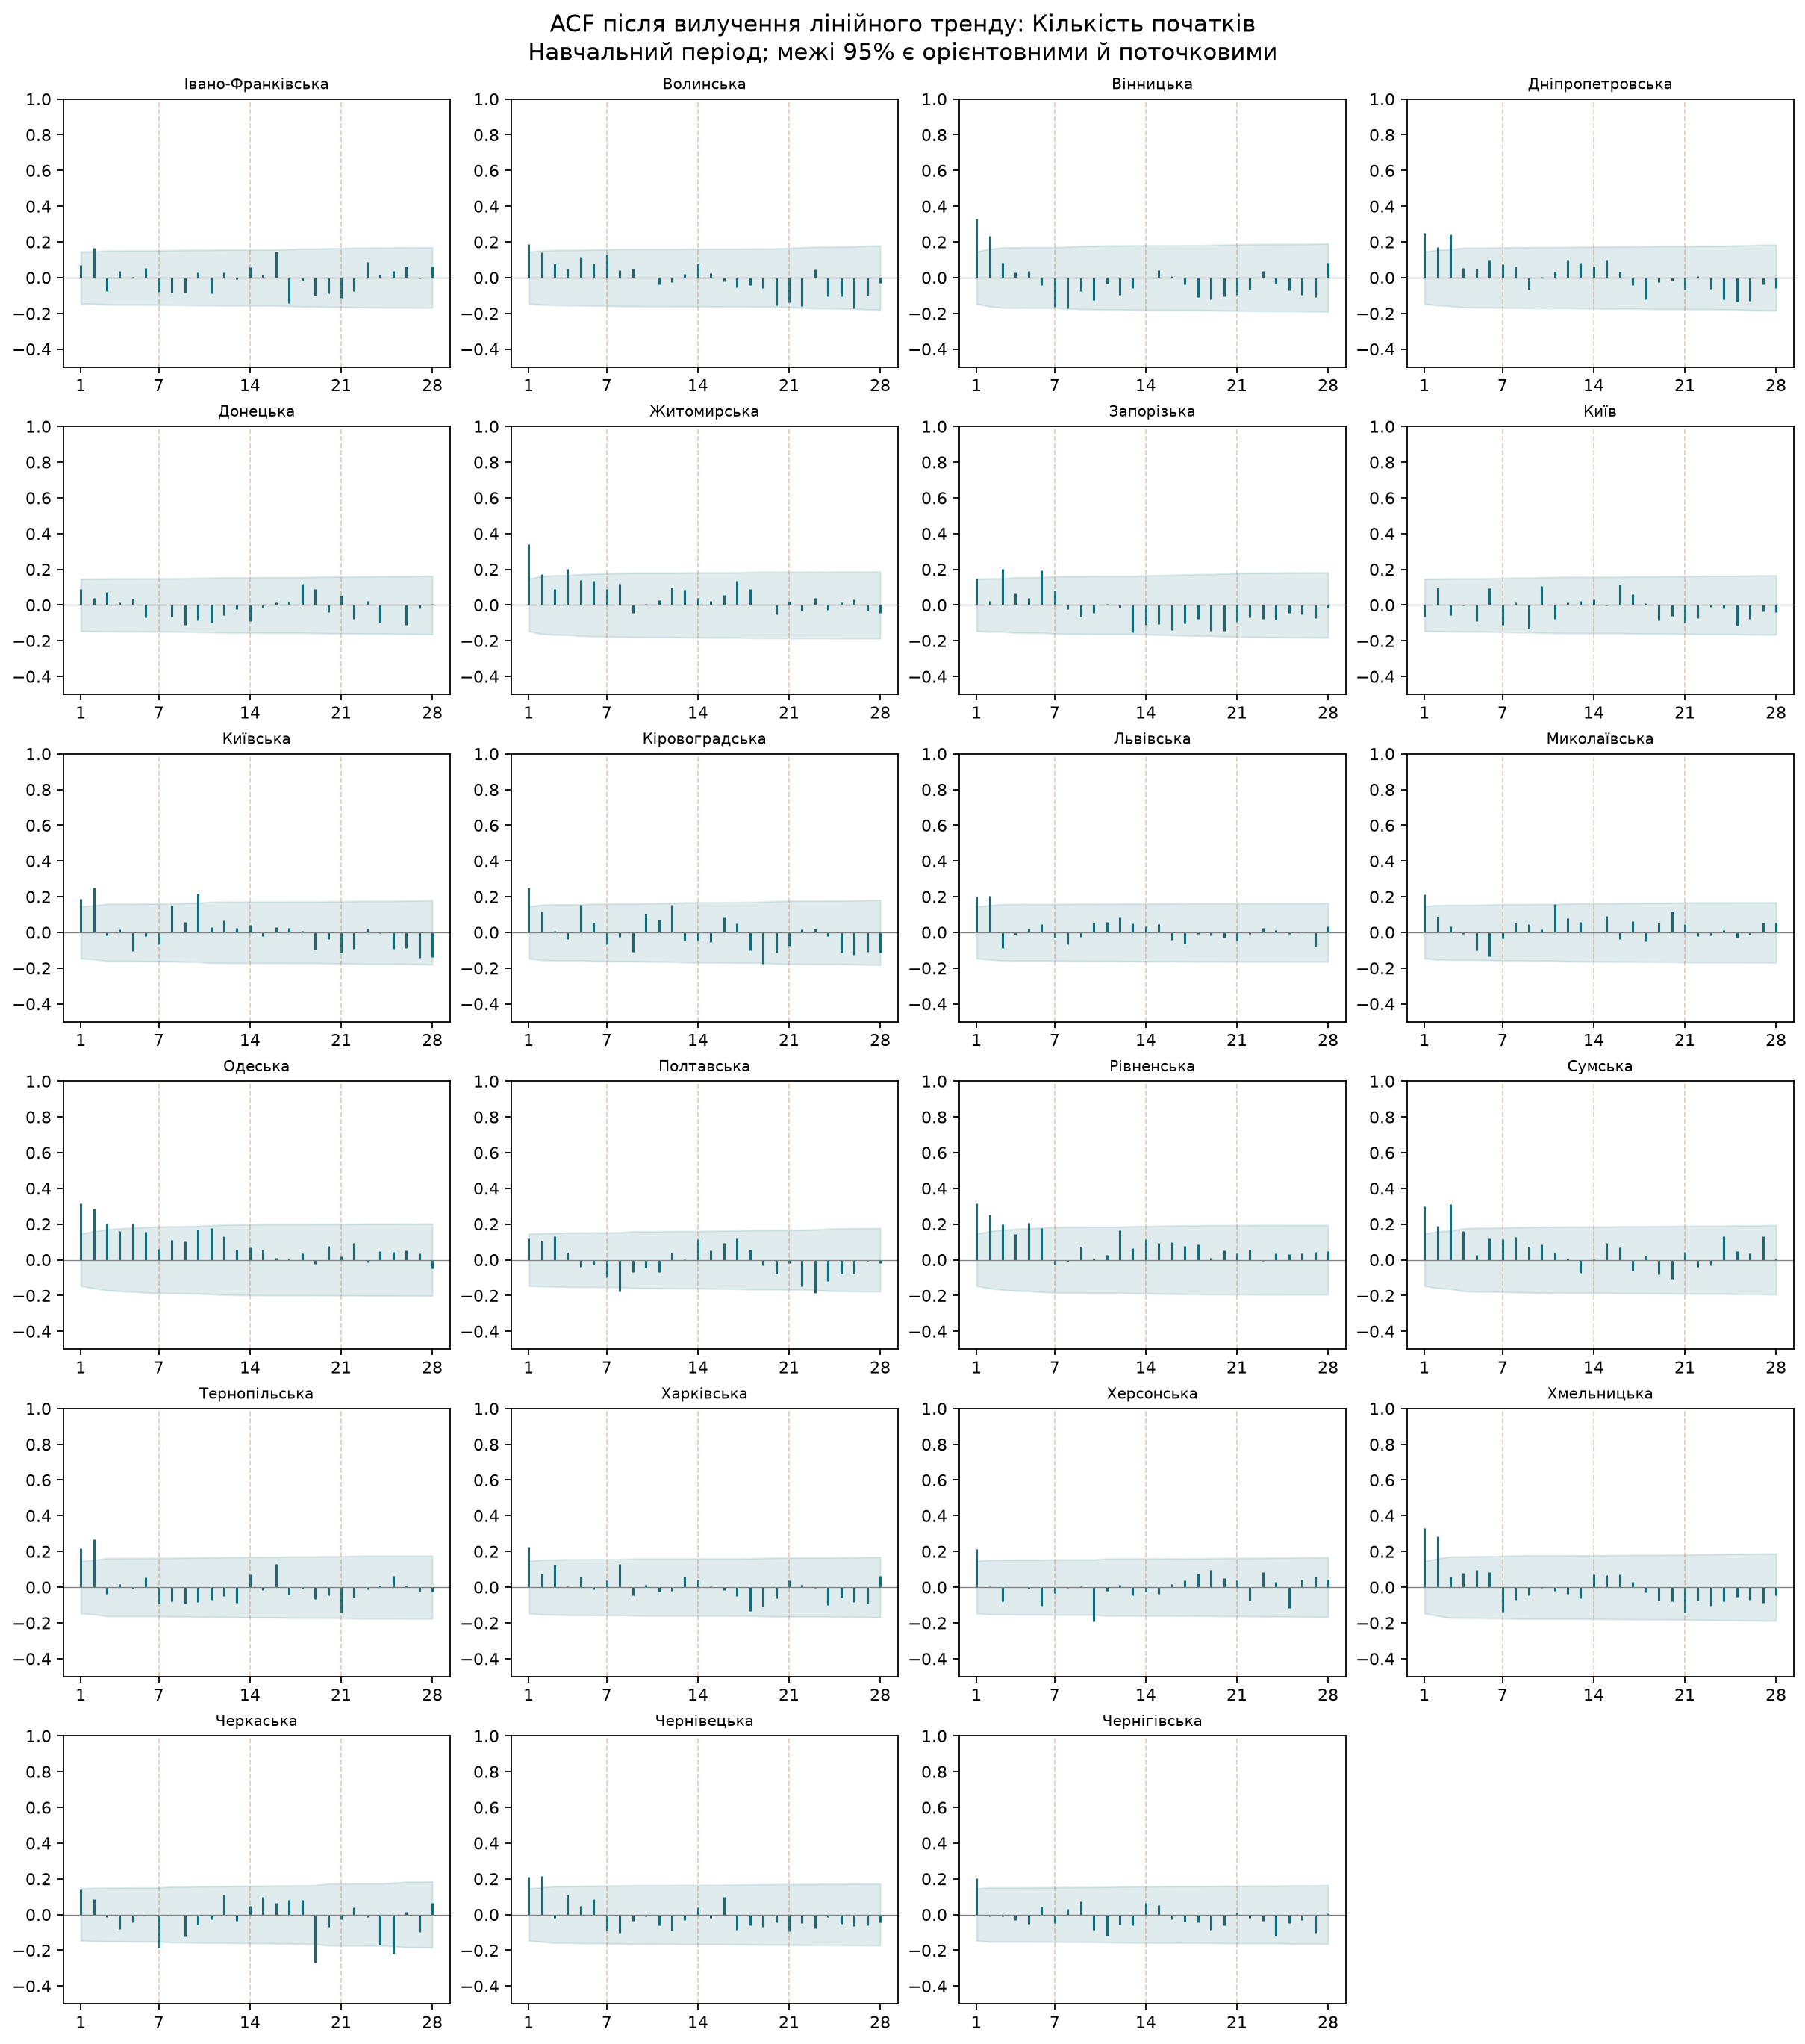

conclusion
переконливої користі сезонності не виявлено                            85
сезонність покращує прогноз, ACF не дає переконливого підтвердження     7
Name: порівнянь, dtype: int64

,region,target,family,nonseasonal_mae,seasonal_mae,nonseasonal_rmse,seasonal_rmse,mae_improvement,relative_mae_improvement,acf_7,acf_7_exploratory_positive,conclusion
28,Київ,count,ARIMA,2.701548,2.668384,3.067262,3.050860,0.033164,0.012276,-0.109521,False,переконливої користі сезонності не виявлено
29,Київ,count,Exponential smoothing,2.497402,2.537574,2.846349,2.890901,-0.040172,-0.016086,-0.109521,False,переконливої користі сезонності не виявлено
30,Київ,hours,ARIMA,1.660148,1.688947,2.100918,2.127313,-0.028799,-0.017347,-0.044932,False,переконливої користі сезонності не виявлено
31,Київ,hours,Exponential smoothing,1.686168,1.725030,2.124035,2.163680,-0.038862,-0.023048,-0.044932,False,переконливої користі сезонності не виявлено


In [6]:
acf = pd.read_csv(REPORTS/'acf.csv')
display(acf.query('lag in [7,14,21]').pivot(index=['region','target'],columns='lag',values='acf').round(3))
display(Image(filename=str(REPORTS/'figures/acf_count.png'),width=900))
comparison = pd.read_csv(REPORTS/'seasonal_comparison.csv')
display(comparison.groupby('conclusion').size().rename('порівнянь'))
display(comparison.query("region == 'Київ'"))

## Чесне оцінювання

Для кожного origin — власний snapshot та до 180 доступних днів. Доступність обмежує останній готовий день, тому горизонт може бути 2–6 кроків. Валідаційні мітки зафіксовано до тесту. Обмеження виходу застосовано до обчислення метрик; дробова кількість є очікуваним значенням. Macro MAE — середнє регіональних MAE, без загального показника годин.

,target,model,macro_mae,macro_rmse,regions,forecast_days
0,count,baseline,2.207319,2.776475,23,643
1,count,selected,2.004518,2.591188,23,643
2,hours,baseline,1.467118,2.067873,23,643
3,hours,selected,1.453168,2.007970,23,643


,target,baseline_mae,selected_mae,relative_improvement,criterion_met
0,count,2.207319,2.004518,0.091877,True
1,hours,1.467118,1.453168,0.009509,False


,region,target,n,mae,rmse,model
0,Івано-Франківська область,count,27,0.370106,0.545839,ets_7
1,Івано-Франківська область,hours,27,0.157745,0.216027,ses
2,Волинська область,count,28,2.087573,2.586370,arima
3,Волинська область,hours,28,2.912478,4.019765,ets_7
4,Вінницька область,count,28,2.449917,3.038899,ets_7
5,Вінницька область,hours,28,1.115539,1.414644,ets_7
6,Дніпропетровська область,count,28,3.585850,4.746959,ets_7
7,Дніпропетровська область,hours,28,0.886713,1.131642,ses
8,Донецька область,count,28,1.314087,1.549729,ses
9,Донецька область,hours,28,1.941602,2.623550,ses


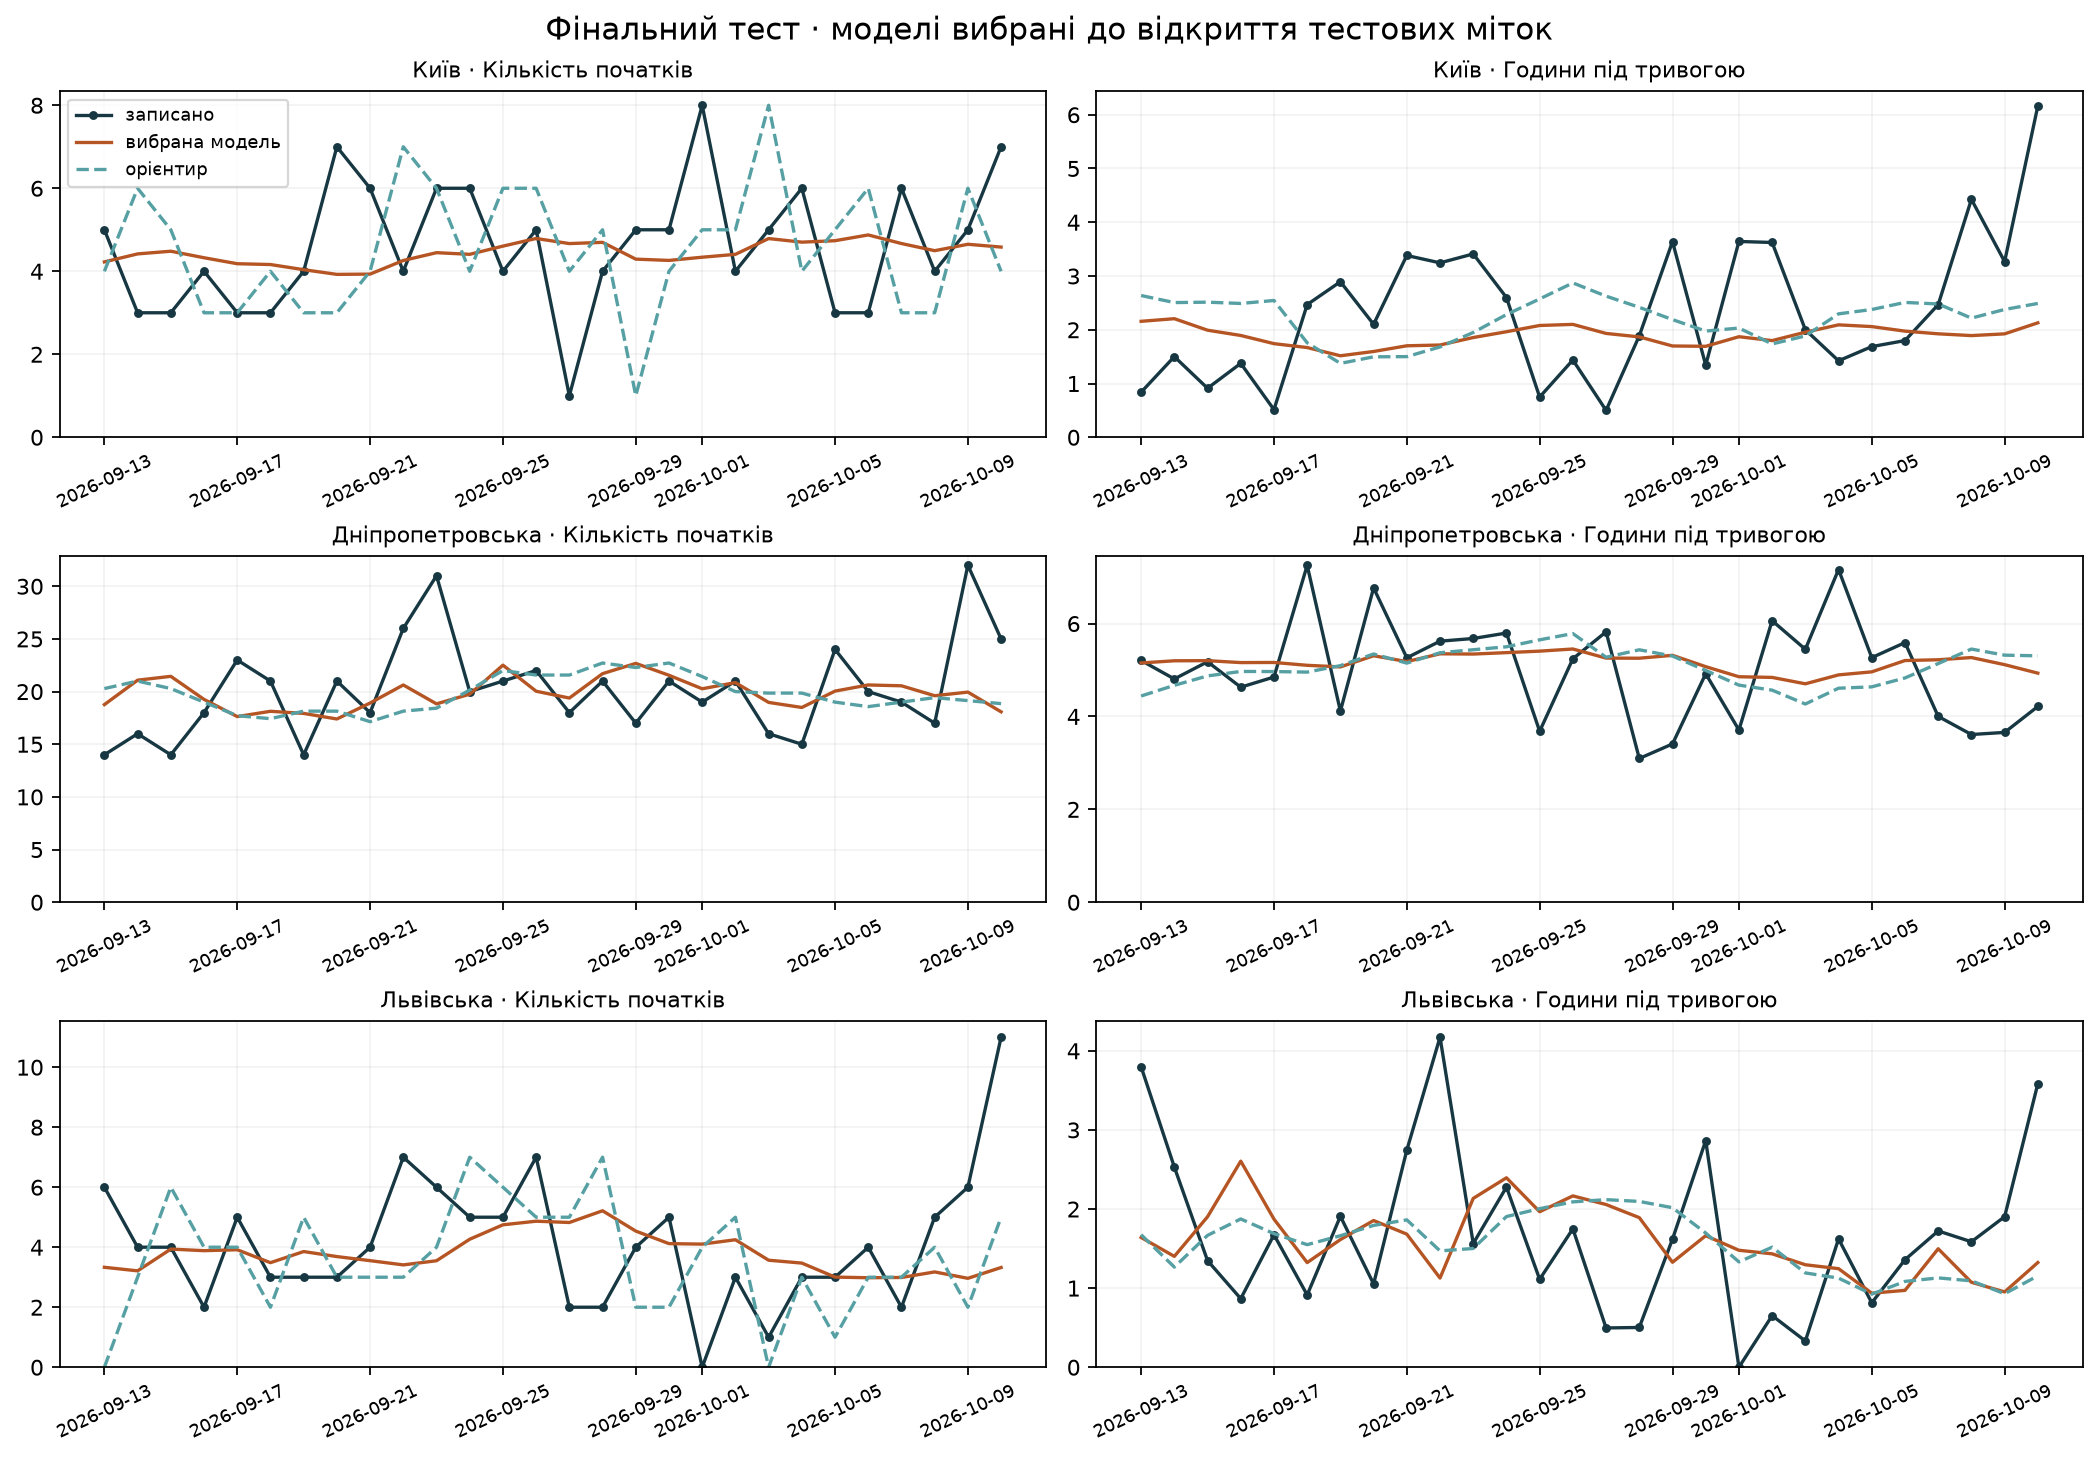

forecast_rows                                                      15722
all_finite                                                          True
nonnegative                                                         True
hours_bounded                                                       True
all_snapshots_before_origin                                         True
max_steps                                                              6
min_steps                                                              2
fallback_forecasts                                                    24
clipped_forecasts                                                     73
test_labels_excluded                                                   1
validation_labels_excluded                                             4
selection_label_snapshot        5c0b2e82dc39171c496726864897a0ae0b012000
selection_label_available_at                        2026-09-12T03:48:54Z
dtype: object

In [7]:
display(pd.read_csv(REPORTS/'test_macro_metrics.csv'))
display(pd.DataFrame(json.loads((REPORTS/'success_criteria.json').read_text())))
display(pd.read_csv(REPORTS/'results_by_region.csv'))
display(Image(filename=str(REPORTS/'figures/forecast_vs_actual.png')))
display(pd.Series(json.loads((REPORTS/'forecast_audit.json').read_text())))

## Приклад відтворення одного прогнозу

Для першого тестового дня в Києві повторюємо тільки вибрану на валідації модель. Входи беруться зі snapshot до origin. Перевіряємо збіг зі збереженим прогнозом. Далі додаємо штучний майбутній рядок: він не повинен змінити минулі входи.

In [8]:
selection = pd.read_csv(REPORTS/'model_selection.csv')
tasks, omissions = make_tasks(ledger,snapshots,protocol['config'],[protocol['test_start']],['Київ'])
task = tasks[0]
display(pd.Series({k:v for k,v in task.items() if k not in ['count','share']}))
predictions = pd.DataFrame(forecast_task(task))
chosen = selection.query("region == 'Київ' and kind == 'selected'")
predictions = predictions.merge(chosen[['region','target','model']],on=['region','target','model'])
saved = pd.read_csv(REPORTS/'test_predictions_selected.csv').query("region == 'Київ' and kind == 'selected'")
saved = saved.loc[saved.date == protocol['test_start']]
check = predictions.merge(saved[['target','prediction']],on='target',suffixes=('_repeated','_saved'))
assert np.allclose(check.prediction_repeated,check.prediction_saved,rtol=0,atol=1e-9)
display(check[['target','model','prediction_repeated','prediction_saved']])
future = ledger.iloc[[-1]].copy()
future['available_at'] = midnight('2026-12-01')
modified = pd.concat([ledger,future],ignore_index=True)
again, _ = make_tasks(modified,snapshots,protocol['config'],[protocol['test_start']],['Київ'])
assert tasks == again
print('Майбутнє не змінило минулі входи; прогноз відтворено.')

region                                                                Київ
date                                                            2026-09-13
origin                                           2026-09-13T00:00:00+03:00
snapshot_sha                      5c0b2e82dc39171c496726864897a0ae0b012000
snapshot_available_at                                 2026-09-12T03:48:54Z
train_start                                                     2026-03-16
train_end                                                       2026-09-11
train_n                                                                180
steps                                                                    2
day_hours                                                             24.0
models                   [last, weekly_naive, mean_7, arima, sarima_7, ...
dtype: object

,target,model,prediction_repeated,prediction_saved
0,count,ses,4.225786,4.225786
1,hours,arima,2.157322,2.157322


Майбутнє не змінило минулі входи; прогноз відтворено.


## Незалежні аудити та висновок

Перерахунок тривалості окремим sweep-line алгоритмом і метрик через стандартний csv/math. Вони не повторюють виробничу функцію оцінювання. 5% поріг досягнуто для кількості, для годин — ні. Потрібні наступні експерименти та новий відкладений період, а не переналаштування за цим тестом. Telegram залишено на наступний етап.

In [9]:
from airraid.audit import independent_aggregation_check
from airraid.reporting import independent_metrics_check
aggregation_check = independent_aggregation_check(DATA,REPORTS)
display({k:v for k,v in aggregation_check.items() if k != 'checked'})
display(independent_metrics_check(REPORTS))
print('Автоматизовані тести: python -m pytest -q')

{'passed': True,
 'cases': 40,
 'method': 'stdlib CSV + independent sweep-line interval union'}

{'passed': True,
 'regional_metric_rows': 92,
 'paired_cases': True,
 'method': 'independent stdlib CSV arithmetic; MAE/RMSE and paired dates'}

Автоматизовані тести: python -m pytest -q
